In [10]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.tsatools import lagmat
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima_process import arma2ma
from IPython.display import display
%matplotlib inline

def read_fred(path):
    d = pd.read_csv(path)
    v = pd.to_numeric(d.iloc[:, 1], errors="coerce")
    ok = v.notna()
    return pd.to_datetime(d.iloc[:, 0][ok]).reset_index(drop=True), v[ok].to_numpy()

def fit_ar(y, p):
    y = np.array(y, float)
    X = sm.add_constant(lagmat(y, p, trim="both"))
    return sm.OLS(y[p:], X).fit()

def ar_forecast(y, p, h):
    y = np.array(y, float)
    return AutoReg(y, lags=p, trend="c").fit().predict(start=len(y), end=len(y) + h - 1)

def band(res, h):
    psi = arma2ma(np.r_[1, -res.params[1:]], [1], lags=h)
    return np.sqrt(res.scale) * np.sqrt(np.cumsum(psi ** 2))

def coef_table(res, names=None):
    names = names or ["intercept"] + [f"phi{k}" for k in range(1, len(res.params))]
    return pd.DataFrame({"estimate": res.params, "std.err": res.bse}, index=names).round(6)

dates, y = read_fred("POPTHM.csv")
h = 60

A

In [11]:
fit = fit_ar(y, 3)
display(coef_table(fit))
print("sigma_hat =", np.sqrt(fit.scale))

,estimate,std.err
intercept,19.484585,3.924890
phi1,2.352792,0.031819
phi2,-1.782578,0.062819
phi3,0.429772,0.031877


sigma_hat = 15.781741240023532


B

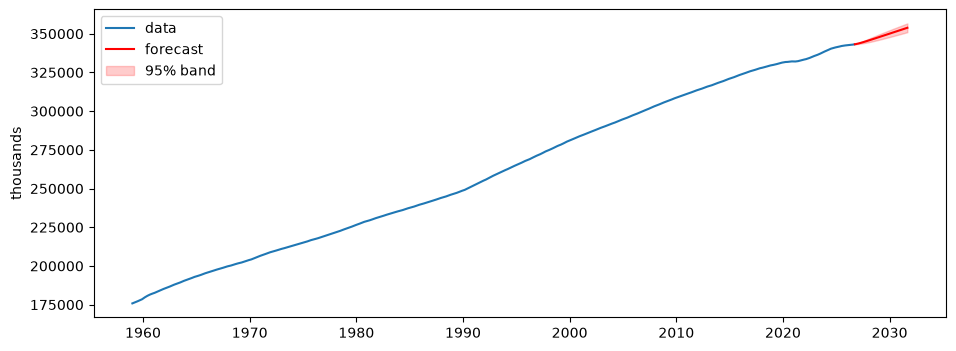

In [12]:
future = pd.date_range(dates.iloc[-1], periods=h + 1, freq="MS")[1:]
pred = ar_forecast(y, 3, h)
se = band(fit, h)

plt.figure(figsize=(11, 4))
plt.plot(dates, y, label="data")
plt.plot(future, pred, "r", label="forecast")
plt.fill_between(future, pred - 1.96 * se, pred + 1.96 * se, color="r", alpha=0.2, label="95% band")
plt.ylabel("thousands")
plt.legend()
plt.show()

The forecast continues the upward trend with a narrow band that widens slowly. This makes sense for a population series. The band is probably too narrow because it ignores uncertainty in the estimated coefficients and assumes growth stays the same.

C

In [13]:
back = fit_ar(y[::-1], 3)
display(coef_table(back, ["alpha0", "alpha1", "alpha2", "alpha3"]))
display(pd.DataFrame({"forward (a)": fit.params, "backward (c)": back.params},
                     index=["intercept", "coef 1", "coef 2", "coef 3"]).round(6))

,estimate,std.err
alpha0,-18.788248,3.921657
alpha1,2.349232,0.031818
alpha2,-1.777413,0.062705
alpha3,0.428190,0.031759


,forward (a),backward (c)
intercept,19.484585,-18.788248
coef 1,2.352792,2.349232
coef 2,-1.782578,-1.777413
coef 3,0.429772,0.428190


The backward coefficients are almost identical to the forward ones. Only the intercept differs, and it flips sign. So the two models are essentially mirror images, as expected for a smoothly trending series.

D

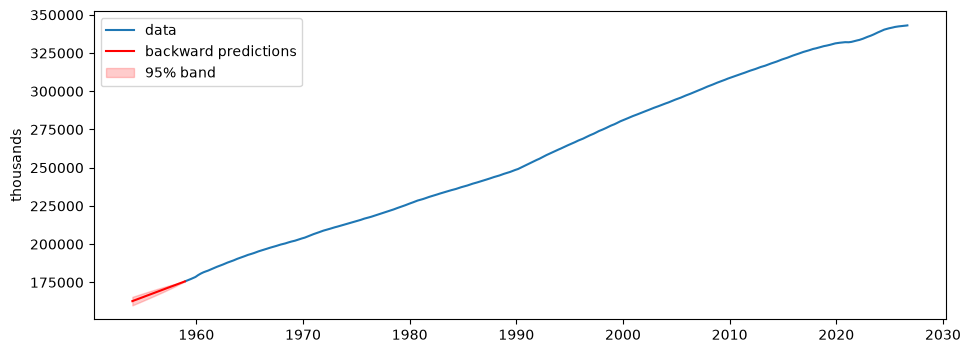

In [14]:
pb = ar_forecast(y[::-1], 3, h)[::-1]
sb = band(back, h)[::-1]
past = pd.date_range(end=dates.iloc[0], periods=h + 1, freq="MS")[:-1]

plt.figure(figsize=(11, 4))
plt.plot(dates, y, label="data")
plt.plot(past, pb, "r", label="backward predictions")
plt.fill_between(past, pb - 1.96 * sb, pb + 1.96 * sb, color="r", alpha=0.2, label="95% band")
plt.ylabel("thousands")
plt.legend()
plt.show()

The predictions decline smoothly into the past with a narrow band. This makes sense because the population was growing then. It is still only an extrapolation from the model.